<div align="center" dir="rtl" style="direction:rtl;text-align:center;">

<p><img src="../src/logo.png" alt="لوگوی مجموعهٔ آزمون‌های آزمایشی هوش مصنوعی" width="400"></p>
<p><strong>مجموعهٔ آزمون‌های آزمایشی هوش مصنوعی</strong></p>
<p>آزمون مرحله 3 دوره دوم</p>
<h1>چشمِ فولادی</h1>
<p>سطح ۲ · بینایی ماشین، ویژگی بافت و MLP</p>
<p><strong>اختاپوس‌ها سه قلب دارند.</strong></p>

</div>

<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## مأموریت شما

کارخانهٔ فولاد سپهر می‌خواهد پیش از بسته‌بندی، سطح هر ورق را با دوربین بازرسی کند. هر تصویر یکی از شش نوع بافت یا عیب سطحی را نشان می‌دهد. شما باید برای هر تصویر، کلاس درست را پیش‌بینی کنید تا بازرس خودکار بتواند ورق‌های نیازمند بررسی را جدا کند.

### کلاس‌ها

| برچسب | نوع بافت |
|---:|---|
| 0 | `crazing` — ترک‌های مویی |
| 1 | `inclusion` — ناخالصی |
| 2 | `patches` — لکه‌ها |
| 3 | `pitted_surface` — سطح حفره‌دار |
| 4 | `rolled-in_scale` — پوستهٔ نورد |
| 5 | `scratches` — خراش |

### داده‌ها

تصویرها خاکستری، با اندازهٔ `200×200` و از نوع `uint8` هستند. هر آرشیو NPZ شامل آرایهٔ `images` است؛ فایل‌های train و validation همچنین آرایهٔ `labels` و `class_names` دارند. آرایهٔ `ids` شناسهٔ اصلی تصویر است و باید بدون تغییر به فایل ارسال منتقل شود.

| فایل | محتوا |
|---|---|
| `data/train/train_data.npz` | ۸۰۴ تصویر برچسب‌دار |
| `data/validation/validation_data.npz` | ۱۷۴ تصویر برچسب‌دار |
| `data/test/test_images.npz` | ۱۷۴ تصویر بدون برچسب |

### چالش و مسیر حل

تعداد نمونه‌ها نسبت به تعداد پیکسل‌ها کم است و تفاوت کلاس‌ها بیشتر در **بافت** تصویر دیده می‌شود. میانگین روشنایی کل تصویر به‌تنهایی کافی نیست؛ آمار محلی، هیستوگرام روشنایی، لبه‌ها و گرادیان‌ها می‌توانند اطلاعات مکملی بدهند.

ویژگی‌ها را از تصویر استخراج کنید و یک **پرسپترون چندلایه (MLP)** بسازید. مدل نهایی فقط می‌تواند از لایه‌های کاملاً متصل استفاده کند. روش‌های تغییر تصویر مانند بازتاب یا چرخش را فقط وقتی به کار ببرید که برچسب را عوض نکنند. آموزش و پیش‌بینی باید روی CPU انجام شود.

### کتابخانه‌ها و محدودیت‌ها

کتابخانه‌های مجاز: `numpy`, `torch`, `matplotlib`, `sklearn`, `scipy`, `PIL`, `seaborn`. مدل نهایی باید MLP باشد. لایه‌های کانولوشنی، شبکه‌های ازپیش‌آموزش‌دیده، Transformer، `torchvision.models` و منابع تصویری بیرونی مجاز نیستند. سقف پیشنهادی زمان `fit + predict` روی CPU ده دقیقه است.

### معیار و نمره‌دهی

معیار **Macro-F1** است؛ F1 هر شش کلاس با وزن برابر میانگین گرفته می‌شود. نمره از رابطهٔ `min(20, 20 * Macro-F1 / 0.897)` به دست می‌آید؛ هدف نمرهٔ کامل Macro-F1 حداقل `0.897` است.

### قالب ارسال

`submission.csv` باید دقیقاً دو ستون `id,prediction` داشته باشد. هر شناسهٔ test باید دقیقاً یک بار درج شود و مقدار `prediction` یکی از برچسب‌های `0` تا `5` باشد. سلول نهایی، آرایهٔ `predictions` را به این قالب تبدیل می‌کند.

</div>

<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۱. بارگذاری و مشاهدهٔ تصویرها

فایل‌های NPZ را بخوانید، ابعاد آرایه‌ها و تعداد نمونه‌های هر کلاس را بررسی کنید. چند تصویر از هر کلاس نمایش دهید تا تفاوت‌های بافتی را ببینید.

</div>

train/validation/test: (804, 200, 200) (174, 200, 200) (174, 200, 200)
0 crazing 134
1 inclusion 134
2 patches 134
3 pitted_surface 134
4 rolled-in_scale 134
5 scratches 134


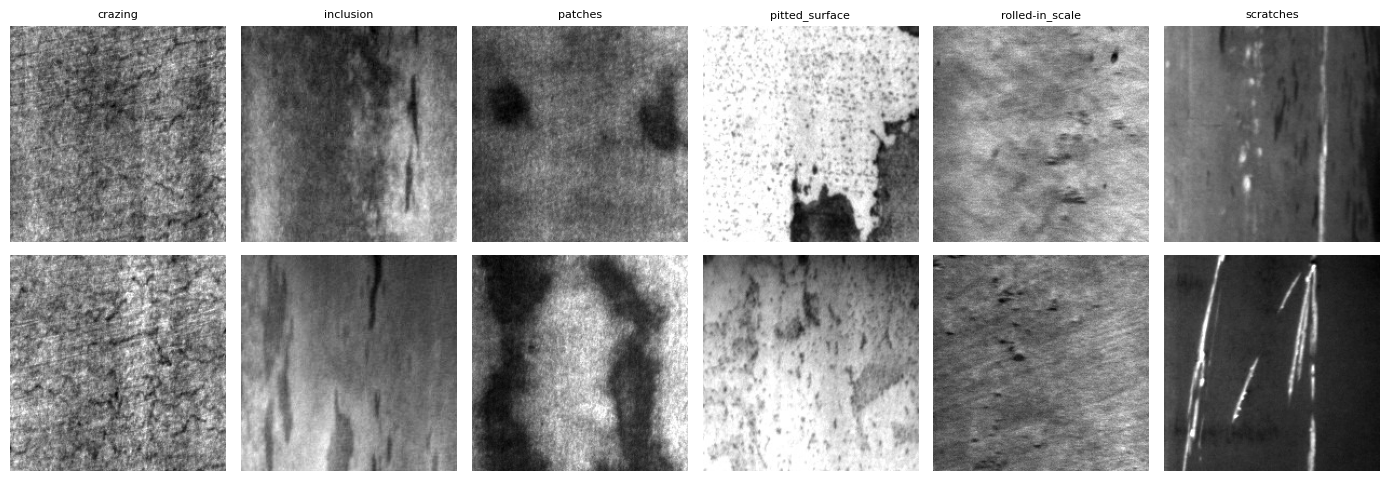

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
DATA=Path("data")
tr=np.load(DATA/"train"/"train_data.npz",allow_pickle=True); va=np.load(DATA/"validation"/"validation_data.npz",allow_pickle=True); te=np.load(DATA/"test"/"test_images.npz",allow_pickle=True)
images,labels=tr["images"],tr["labels"]; validation_images,validation_labels=va["images"],va["labels"]; test_images=te["images"]
class_names=[str(x) for x in tr["class_names"]]
print("train/validation/test:",images.shape,validation_images.shape,test_images.shape)
for i,name in enumerate(class_names): print(i,name,int((labels==i).sum()))
fig,axes=plt.subplots(2,6,figsize=(14,5))
rng=np.random.default_rng(0)
for c,name in enumerate(class_names):
 idx=np.flatnonzero(labels==c)[:2]
 for r,j in enumerate(idx): axes[r,c].imshow(images[j],cmap="gray");axes[r,c].axis("off")
 axes[0,c].set_title(name,fontsize=8)
plt.tight_layout();plt.show()


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۲. طراحی MLP

کلاس `MLP` را با لایه‌های کاملاً متصل تعریف کنید. ورودی آن بردار ویژگی استخراج‌شده و خروجی آن شش امتیاز کلاس باشد.

</div>

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader,TensorDataset

class MLP(nn.Module):
    def __init__(self,input_size,num_classes=6):
        super().__init__()
        # TODO: Define a fully connected network with regularization.
        raise NotImplementedError
    def forward(self,x):
        # TODO: Return one logit per class.
        raise NotImplementedError


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۳. استخراج ویژگی‌های بافتی

تصویر را به برداری عددی تبدیل کنید. آمار ناحیه‌ای، توزیع روشنایی و تغییرات شدت در جهت‌های مختلف را بررسی کنید. تعداد ویژگی‌ها برای همهٔ تصویرها باید ثابت باشد.

</div>

In [ ]:
from scipy.ndimage import sobel

def extract_features(img):
    """Return one fixed-length texture descriptor for a 200x200 grayscale image."""
    # TODO: Combine local brightness/contrast, intensity histogram, and edge/gradient features.
    raise NotImplementedError

def extract_feature_matrix(batch):
    return np.stack([extract_features(img) for img in batch]).astype(np.float32)


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۴. افزایش داده

نسخه‌های تبدیل‌شده را فقط با تبدیل‌هایی بسازید که نوع عیب را حفظ می‌کنند. تصویر و برچسب متناظر باید در یک ترتیب باقی بمانند.

</div>

In [ ]:
def augment_images(images,labels):
    # TODO: Return original images and label-preserving flips/rotations with matching labels.
    raise NotImplementedError


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۵. آموزش مدل در کلاس Solution

`fit` باید ویژگی‌ها را استخراج، مقیاس‌بندی و مدل MLP را آموزش دهد. `predict` باید دقیقاً همان استخراج و مقیاس‌بندی را با آماره‌های ذخیره‌شده انجام دهد.

</div>

In [ ]:
class Solution:
    def __init__(self,seed=42):
        self.seed=seed
        self.mean_=None
        self.scale_=None
        self.model=None

    def fit(self,data):
        images=np.asarray(data["images"]); labels=np.asarray(data["labels"],dtype=np.int64)
        # TODO: Create a stratified early-stopping split, extract/augment features,
        # standardize using training features, then train the MLP on CPU.
        raise NotImplementedError

    def predict(self,data):
        images=np.asarray(data["images"])
        # TODO: Reuse stored scaling statistics and return one class id per image.
        raise NotImplementedError


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۶. ارزیابی محلی

با کنارگذاشتن بخشی از train، Macro-F1 و نمرهٔ تخمینی را محاسبه کنید. پس از انتخاب روش، مدل نهایی را روی train و validation با هم آموزش دهید.

</div>

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import time
tr_idx,va_idx=train_test_split(np.arange(len(labels)),test_size=0.2,random_state=1,stratify=labels)
t0=time.time();solution=Solution();solution.fit({"images":images[tr_idx],"labels":labels[tr_idx]});val_pred=solution.predict({"images":images[va_idx]})
f1=f1_score(labels[va_idx],val_pred,average="macro",zero_division=0)
score=min(20.0,20.0*f1/0.897)
print(f"Macro-F1={f1:.4f}; estimated score={score:.2f}/20; runtime={time.time()-t0:.1f}s")


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۷. ساخت فایل ارسال

پیش‌بینی test را در متغیر `predictions` قرار دهید و فایل نهایی را با شناسه‌های آرشیو تست بسازید.

</div>

In [ ]:
import csv
# Refit on train and validation together, then create the shared submission format.
all_images=np.concatenate([images,validation_images]);all_labels=np.concatenate([labels,validation_labels])
final_solution=Solution();final_solution.fit({"images":all_images,"labels":all_labels})
predictions=np.asarray(final_solution.predict({"images":test_images}),dtype=int)
test_ids=te["ids"]
assert len(predictions)==len(test_ids) and set(np.unique(predictions)).issubset(set(range(6)))
with open("submission.csv","w",newline="",encoding="utf-8") as f:
    writer=csv.writer(f);writer.writerow(["id","prediction"]);writer.writerows(zip(test_ids,predictions.tolist()))
print(f"Created submission.csv with {len(predictions)} rows.")
